# Reynolds → Stage 1 healthy reconstruction error: causal diagnostic study

**Question:** Do changes in Reynolds regime or Reynolds level affect healthy spectral reconstruction errors, and are observed relationships robust to measured time structure?

**Data:** archived pretrained Stage 1 outputs from validation run `1212_1` (no training). Only fully healthy 40-observation windows are included. The 40-step requirement belongs to model inference, **not** to the analysis horizon.

**Identification warning:** one nonrandomized experimental run, unmeasured pump state/temperature/pressure, and time-varying acoustic conditions prevent definitive causal identification. We estimate adjusted associations, pre-trends, transition contrasts, and sensitivity diagnostics. A flow change may be an operating-regime intervention, not an isolated Reynolds intervention.

**Critical:** Never calculate first differences across gaps introduced by healthy-only filtering. Adjacent original observation indices **and** consecutive timestamps are checked.

In [2]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display
from scipy import stats

# Project structure:
# project_root/
# ├── data/
# ├── documents/
# ├── models/
# ├── notebooks/   <- notebook runs here
# ├── results/
# ├── src/
# └── tests/

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

RESULTS_DIR = ROOT / "results"

CANDIDATES = [
    RESULTS_DIR / "stage1_reynolds_tracking",
    RESULTS_DIR,
]

DATA_DIR = next(
    (p for p in CANDIDATES
     if (p / "1212_1_healthy_stage1_endpoints.csv").exists()),
    None
)

if DATA_DIR is None:
    raise FileNotFoundError(
        f"Cannot find 1212_1_healthy_stage1_endpoints.csv "
        f"under {RESULTS_DIR}"
    )

OUT = RESULTS_DIR / "reynolds_causal_results"
OUT.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Reading:", DATA_DIR)
print("Saving to:", OUT)


Project root: /home/ubuntu/notebooks/Leak_Detection
Reading: /home/ubuntu/notebooks/Leak_Detection/results/stage1_reynolds_tracking
Saving to: /home/ubuntu/notebooks/Leak_Detection/results/reynolds_causal_results


## 1. Audit observed variables, coverage and temporal adjacency
Only available fields are used. Potential confounders such as temperature, pump speed and pressure cannot be adjusted for unless independently measured. `Reynolds` may encode operating changes, and it is not assumed randomized.

Rows: 7567 columns: ['observation_index', 'datetime', 'Reynolds', 'delta_Reynolds', 'abs_delta_Reynolds', 'endpoint_RMSE', 'endpoint_MAE', 'actual_spectrum_RMS', 'relative_RMSE', 'is_transition', 'transition_within_window', 'Reynolds_bin', 'steps_since_Re_change']
Original observation index range: 40 10801
Re range: 0.0 150.0
Duplicate observation indices: 0
Missing values:


,missing
Reynolds,0
endpoint_RMSE,0
datetime,0


Reynolds distribution:


,Reynolds
count,7567.000000
mean,55.730317
std,48.490302
min,0.000000
25%,14.843750
50%,41.666668
75%,100.000000
max,150.000000


Healthy-only gaps (not necessarily single missing samples): 5


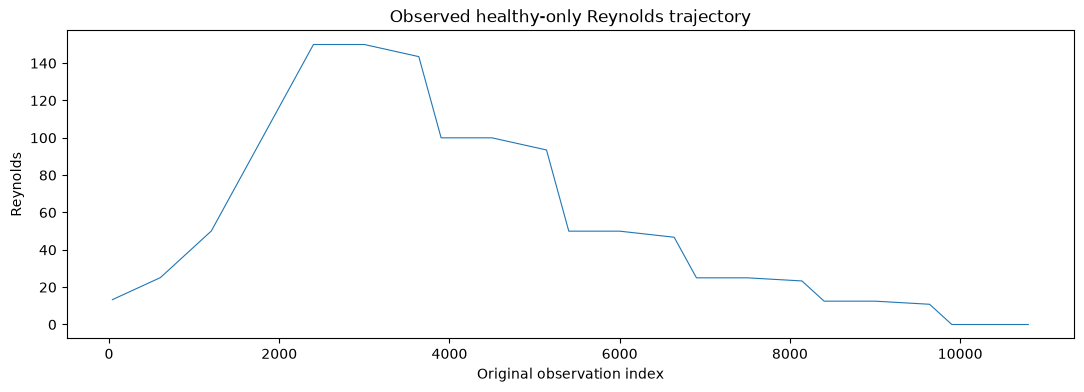

In [3]:
df = pd.read_csv(DATA_DIR/'1212_1_healthy_stage1_endpoints.csv').sort_values('observation_index').reset_index(drop=True)
df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')
print('Rows:',len(df),'columns:',df.columns.tolist())
print('Original observation index range:',df.observation_index.min(),df.observation_index.max())
print('Re range:',df.Reynolds.min(),df.Reynolds.max())
print('Duplicate observation indices:',df.observation_index.duplicated().sum())
print('Missing values:'); display(df[['Reynolds','endpoint_RMSE','datetime']].isna().sum().to_frame('missing'))
print('Reynolds distribution:'); display(df.Reynolds.describe().to_frame())
print('Healthy-only gaps (not necessarily single missing samples):',int((df.observation_index.diff().fillna(1)>1).sum()))
fig,ax=plt.subplots(figsize=(13,4));ax.plot(df.observation_index,df.Reynolds,lw=.8);ax.set(xlabel='Original observation index',ylabel='Reynolds',title='Observed healthy-only Reynolds trajectory');plt.show()


### Interpretation — Data audit and sampling
There are **7,567 healthy-only Stage 1 endpoints** from a single validation run, covering Reynolds **0–150**, with no missing values in the three core fields or duplicate observation indices. The nominal sampling interval is **1 second**. The five gaps in the healthy-only sequence matter: differencing across them would incorrectly compare nonadjacent times. These 7,567 points are temporally dependent, not independent experimental replications. The coverage plot is descriptive; it cannot establish what unrecorded conditions changed during the run.

## 2. Correct first differences: consecutive original observations only
The `delta_Reynolds` stored in the source may refer to original rows. Here we **recalculate** changes only when consecutive retained healthy endpoints correspond to adjacent original observations. Timestamp checks detect discontinuities; no differencing across leak periods.

In [4]:
df['index_gap']=df.observation_index.diff()
df['time_gap_s']=df.datetime.diff().dt.total_seconds()
valid_gaps=df.loc[df.index_gap.eq(1),'time_gap_s'].dropna()
nominal_dt=float(valid_gaps.median()) if len(valid_gaps) else np.nan
print('Nominal sampling interval (s):',nominal_dt)
df['adjacent']=df.index_gap.eq(1) & df.time_gap_s.gt(0)
if np.isfinite(nominal_dt):df['adjacent'] &= df.time_gap_s.between(.5*nominal_dt,1.5*nominal_dt)
for col in ['Reynolds','endpoint_RMSE','relative_RMSE','endpoint_MAE']:
    df['d_'+col]=df[col].diff().where(df.adjacent)
df['abs_d_Reynolds']=df.d_Reynolds.abs()
df['abs_d_endpoint_RMSE']=df.d_endpoint_RMSE.abs()
print('Valid adjacent healthy pairs:',int(df.adjacent.sum()),'of',len(df)-1)
print('Excluded cross-gap pairs:',int((~df.adjacent).sum()-1))


Nominal sampling interval (s): 1.0
Valid adjacent healthy pairs: 7561 of 7566
Excluded cross-gap pairs: 5


### Interpretation — Valid first differences
The adjacency audit retained **7,561 valid consecutive healthy pairs** and excluded **five cross-gap pairs**. This is the appropriate denominator for instantaneous first-difference analysis. Importantly, the later transition definition is based on **per-sample Reynolds changes**, not necessarily the full physical transition from one stable flow regime to another.

## 3. Descriptive associations and visualizations
Pearson/Spearman coefficients are descriptive, not causal. Scatterplots are sampled only for display; all eligible observations enter the correlations.

,x,y,n,pearson,spearman
0,Reynolds,endpoint_RMSE,7567,0.4935,0.6276
1,abs_d_Reynolds,endpoint_RMSE,7561,0.4612,0.3745
2,d_Reynolds,d_endpoint_RMSE,7561,-0.0021,-0.0035
3,abs_d_Reynolds,d_endpoint_RMSE,7561,0.0012,-0.0012
4,abs_d_Reynolds,abs_d_endpoint_RMSE,7561,0.0412,0.0302
5,Reynolds,relative_RMSE,7567,0.2590,0.2622


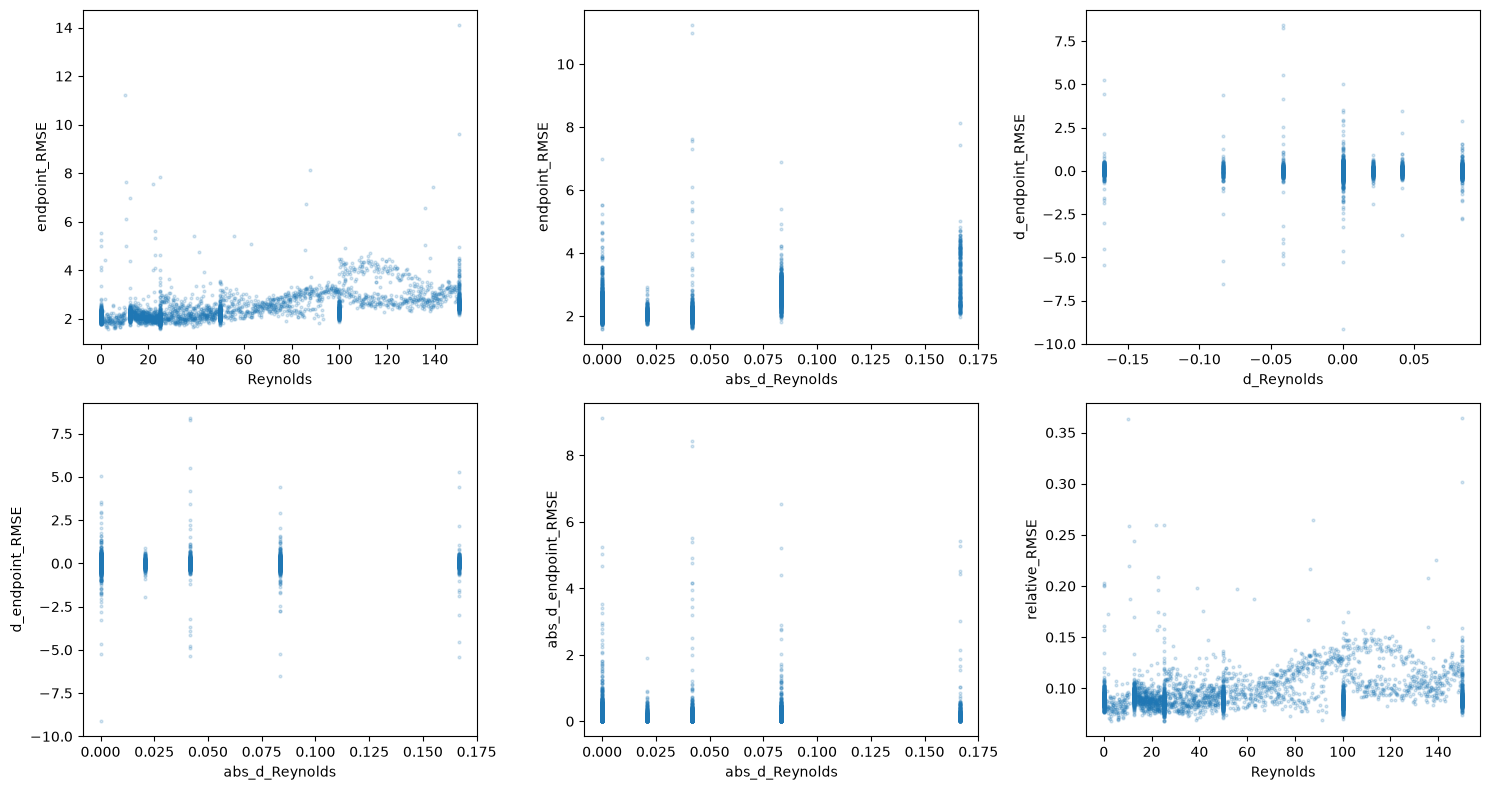

In [5]:
pairs=[('Reynolds','endpoint_RMSE'),('abs_d_Reynolds','endpoint_RMSE'),('d_Reynolds','d_endpoint_RMSE'),('abs_d_Reynolds','d_endpoint_RMSE'),('abs_d_Reynolds','abs_d_endpoint_RMSE'),('Reynolds','relative_RMSE')]
rows=[]
for x,y in pairs:
    z=df[[x,y]].dropna()
    rows.append(dict(x=x,y=y,n=len(z),pearson=z[x].corr(z[y]),spearman=z[x].corr(z[y],method='spearman')))
assoc=pd.DataFrame(rows);display(assoc.round(4));assoc.to_csv(OUT/'associations.csv',index=False)
fig,axes=plt.subplots(2,3,figsize=(15,8))
for ax,(x,y) in zip(axes.flat,pairs):
    z=df[[x,y]].dropna();z=z.sample(min(4000,len(z)),random_state=42)
    ax.scatter(z[x],z[y],s=4,alpha=.18);ax.set(xlabel=x,ylabel=y)
plt.tight_layout();plt.savefig(OUT/'association_scatterplots.png',dpi=140);plt.show()


### Interpretation — Associations and scatterplots
- Reynolds level vs endpoint RMSE: **Pearson 0.4935; Spearman 0.6276**. Higher Reynolds tends to accompany greater healthy reconstruction error; the relationship is nonlinear and clustered by operating regime.
- Absolute per-sample Reynolds change vs RMSE: **0.4612**. This is an association with the **error level**, not evidence that a flow change caused an immediate error increase.
- Signed ΔRe vs ΔRMSE: **−0.0021**; |ΔRe| vs ΔRMSE: **0.0012**; |ΔRe| vs |ΔRMSE|: **0.0412**. These provide essentially no evidence of a strong *instantaneous linear* response in aggregate error.
- Reynolds vs relative RMSE: **0.2590**; the level association is not entirely eliminated by normalizing by spectral magnitude.

**Critical limitation:** The ΔRe axis spans small per-second increments (roughly 0.17 in Reynolds units), whereas Reynolds spans 0–150. These are gradual ramp increments, not jumps of 50 or 100 Reynolds units. A per-second difference can be near zero while the cumulative effect of a long ramp is substantial. Do not interpret near-zero first-difference correlations as disproving delayed or cumulative effects. Correlations alone do not control for time or pump/operating state.

## 4. Confounding diagnostics: regime, time and overlap
A single trajectory cannot generally distinguish Reynolds level from time trends if each level occurs only in one contiguous segment. We measure how much the same Reynolds regimes recur over time. Do not treat many adjacent points as independent experiments.

In [6]:
df['time_fraction']=(df.observation_index-df.observation_index.min())/(df.observation_index.max()-df.observation_index.min())
df['time_quartile']=pd.cut(df.time_fraction,bins=[-0.001,.25,.5,.75,1.001],labels=['Q1','Q2','Q3','Q4'])
df['Re_band']=pd.cut(df.Reynolds,bins=[-np.inf,10,25,50,75,100,125,np.inf],right=False)
coverage=pd.crosstab(df.Re_band,df.time_quartile)
display(coverage);coverage.to_csv(OUT/'reynolds_time_coverage.csv')
print('Confounding flags:')
print('Reynolds–time Pearson correlation:',round(df.Reynolds.corr(df.time_fraction),3))
print('Re bands appearing in >=2 time quartiles:',int((coverage.gt(0).sum(axis=1)>=2).sum()),'of',len(coverage))
print('Note: even repeated levels can have different unobserved operating conditions.')


time_quartile,Q1,Q2,Q3,Q4
Re_band,,,,
"[-inf, 10.0)",0,0,0,1140
"[10.0, 25.0)",561,0,0,883
"[25.0, 50.0)",600,0,861,0
"[50.0, 75.0)",300,169,580,0
"[75.0, 100.0)",300,112,0,0
"[100.0, 125.0)",300,749,0,0
"[125.0, inf)",630,382,0,0


Confounding flags:
Reynolds–time Pearson correlation: -0.567
Re bands appearing in >=2 time quartiles: 6 of 7
Note: even repeated levels can have different unobserved operating conditions.


### Interpretation — Time confounding and limited overlap
**Reynolds and experimental time correlate −0.567.** The coverage table shows pronounced separation: the lowest Reynolds band (<10) occurs only in Q4, while the highest (≥125) occurs only in Q1–Q2. Although six of seven bands appear in at least two quartiles, this is not balanced overlap or randomized assignment. Consequently, Reynolds-level effects are hard to separate from drift, time-varying operating conditions, and changes in the experimental protocol. A time-polynomial adjustment does not guarantee removal of confounding. This is a central limitation of any causal claim from this run.

## 5. Time-series regression with HAC standard errors
Models estimate *conditional associations*. Include nonlinear Reynolds level (quadratic), flow changes, and a flexible time trend. HAC/Newey-West covariance accounts approximately for serial correlation, but cannot eliminate unmeasured confounding. Level and change coefficients may be unstable when collinear. Compare naive vs time-adjusted models.

In [7]:
def fit_hac(form, cols, label, maxlags=60):
    z=df[cols+['endpoint_RMSE']].dropna().copy()
    if len(z)<max(100,5*len(cols)):return None
    X=sm.add_constant(z[cols],has_constant='add')
    result=sm.OLS(z.endpoint_RMSE,X).fit(cov_type='HAC',cov_kwds={'maxlags':min(maxlags,len(z)//5)})
    tab=pd.DataFrame({'term':result.params.index,'coef':result.params.values,'se_HAC':result.bse.values,'p_HAC':result.pvalues.values,'model':label,'n':len(z),'R2':result.rsquared})
    return tab,result
scale=100.
df['Re_100']=df.Reynolds/scale;df['Re_100_sq']=df.Re_100**2
df['abs_d_Re_100']=df.abs_d_Reynolds/scale
df['t']=df.time_fraction;df['t2']=df.t**2;df['t3']=df.t**3
specs=[('Naive level',['Re_100','Re_100_sq']),('Level + time',['Re_100','Re_100_sq','t','t2','t3']),('Level + transition + time',['Re_100','Re_100_sq','abs_d_Re_100','t','t2','t3'])]
results=[]
for name,cols in specs:
    fitted=fit_hac(None,cols,name)
    if fitted:
        table,res=fitted;results.append(table);print(name,'n=',int(res.nobs),'R2=',round(res.rsquared,3))
regression=pd.concat(results,ignore_index=True);display(regression.round(5));regression.to_csv(OUT/'hac_regressions.csv',index=False)
print('Interpretation: coefficient changes across specifications signal sensitivity; neither model identifies a causal effect by itself.')


Naive level n= 7567 R2= 0.244
Level + time n= 7567 R2= 0.271
Level + transition + time n= 7561 R2= 0.366


,term,coef,se_HAC,p_HAC,model,n,R2
0,const,2.04865,0.03488,0.00000,Naive level,7567,0.24375
1,Re_100,0.66741,0.19454,0.00060,Naive level,7567,0.24375
2,Re_100_sq,-0.04136,0.12791,0.74641,Naive level,7567,0.24375
3,const,1.68098,0.09471,0.00000,Level + time,7567,0.27109
4,Re_100,3.16194,0.62737,0.00000,Level + time,7567,0.27109
5,Re_100_sq,-1.11607,0.28457,0.00009,Level + time,7567,0.27109
6,t,-7.98249,2.43789,0.00106,Level + time,7567,0.27109
7,t2,17.29390,5.27858,0.00105,Level + time,7567,0.27109
8,t3,-8.86928,2.84097,0.00180,Level + time,7567,0.27109
9,const,1.83125,0.07230,0.00000,Level + transition + time,7561,0.36593


Interpretation: coefficient changes across specifications signal sensitivity; neither model identifies a causal effect by itself.


### Interpretation — HAC regressions
The naive Reynolds-level model has **R²=0.244**; adding cubic time gives **R²=0.271**; adding |ΔRe| raises this to **R²=0.366**. In the naive model, the linear Reynolds term is positive (**0.667 per 100 Reynolds units**, p≈0.00060), but the quadratic term is not significant. With time adjustment, the Reynolds terms change markedly (**3.162** linear, **−1.116** quadratic), indicating specification sensitivity. In the model also containing |ΔRe|, the Reynolds terms become nonsignificant (**p=0.256 and 0.950**) while |ΔRe| is associated with RMSE (**coefficient 462.84 per 100-unit ΔRe; p<0.001**). Because actual ΔRe values are only around 0.17 or less per step, the seemingly enormous coefficient reflects the chosen scaling: a 0.1-unit ΔRe corresponds to about **0.463 RMSE units** in that specification.

**Interpretation:** This is a conditional *level* association, not evidence that ΔRe instantaneously increases RMSE. Correlated Reynolds, ramp status, and time variables, plus omitted operating conditions, make coefficients unstable. HAC standard errors address serial correlation approximately; they do not eliminate confounding, repair weak overlap, or create independent experimental runs. The three model R² values are in-sample and do not establish causal validity.

## 6. Within-local-period first-difference regression
First differencing removes **time-invariant** local offsets, not simultaneous time-varying confounders. Evaluate whether flow changes coincide with RMSE changes; include direction and magnitude in separate models to avoid unnecessary collinearity.

In [8]:
d=df[df.adjacent].copy();d['dRe_100']=d.d_Reynolds/100;d['abs_dRe_100']=d.abs_d_Reynolds/100
out=[]
for name,cols in [('Signed change',['dRe_100']),('Magnitude of change',['abs_dRe_100']),('Signed + magnitude',['dRe_100','abs_dRe_100'])]:
    z=d[['d_endpoint_RMSE']+cols].dropna();X=sm.add_constant(z[cols]);r=sm.OLS(z.d_endpoint_RMSE,X).fit(cov_type='HAC',cov_kwds={'maxlags':min(60,len(z)//5)})
    for term in r.params.index:out.append(dict(model=name,term=term,coef=r.params[term],se_HAC=r.bse[term],p_HAC=r.pvalues[term],n=len(z)))
diff_reg=pd.DataFrame(out);display(diff_reg.round(5));diff_reg.to_csv(OUT/'difference_regressions.csv',index=False)


,model,term,coef,se_HAC,p_HAC,n
0,Signed change,const,0.00138,0.00139,0.32322,7561
1,Signed change,dRe_100,-1.88705,1.82146,0.30020,7561
2,Magnitude of change,const,0.00090,0.00189,0.63485,7561
3,Magnitude of change,abs_dRe_100,1.31176,2.60060,0.61398,7561
4,Signed + magnitude,const,0.00119,0.00202,0.55648,7561
5,Signed + magnitude,dRe_100,-1.73161,1.78427,0.33180,7561
6,Signed + magnitude,abs_dRe_100,0.53344,2.62137,0.83875,7561


### Interpretation — First-difference regressions
Neither signed ΔRe (**p=0.300**) nor absolute ΔRe (**p=0.614**) predicts an immediate signed ΔRMSE in the one-predictor models. In the combined model, signed and absolute change remain nonsignificant (**p=0.332 and 0.839**). These results agree with the near-zero first-difference correlations: no convincing **same-sample linear response** is detected. They do **not** rule out slower responses, accumulation across a Reynolds ramp, nonlinear threshold effects, or frequency-specific residual changes. First differencing removes constant offsets but does not automatically control time-varying confounders.

## 7. Transition event study with pre-trend and placebo leads
We identify relatively large flow changes from the *empirical distribution* of valid adjacent `|ΔRe|`, enforce nonoverlapping event neighborhoods, and require all event-window observations to be consecutive healthy original observations. For each event, subtract the mean RMSE in the pre-event reference interval. Pre-event movement suggests anticipation, confounding, or timing problems. This is an **event-aligned descriptive study**, not a randomized causal event study.

Threshold and horizon are tunable; results should be checked for sensitivity. Event count, direction, and coverage are always reported.

Transition threshold: 95th percentile of nonzero adjacent |ΔRe| = 0.16667000000000343
Candidate transitions: 185 usable independent-spaced events: 7


,event_id,observation_index,datetime,dRe,Re_before,Re_after
0,0,3670,2023-12-12 17:01:09,-0.166670,138.666670,138.500000
1,1,3740,2023-12-12 17:02:19,-0.166680,127.000010,126.833330
2,2,3854,2023-12-12 17:04:13,-0.166680,108.000010,107.833330
3,3,5170,2023-12-12 17:26:09,-0.166680,88.666670,88.499990
4,4,5232,2023-12-12 17:27:11,-0.166672,78.333336,78.166664
5,5,5295,2023-12-12 17:28:14,-0.166672,67.833336,67.666664
6,6,5381,2023-12-12 17:29:40,-0.166670,53.500000,53.333330


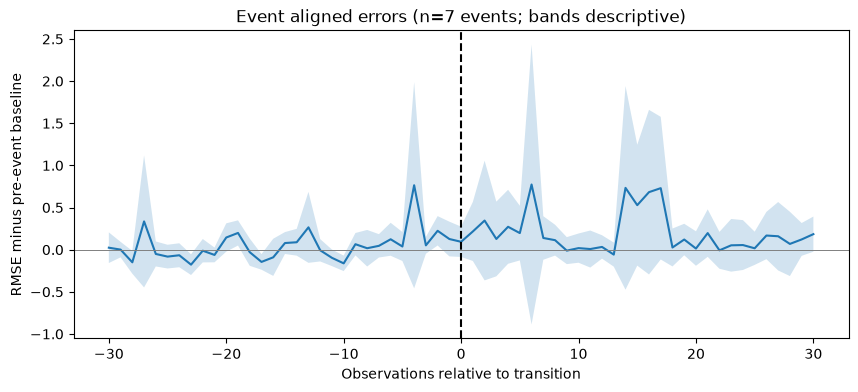

Pre-event placebo mean vs reference: 0.161627967573696 Post-event mean: 0.22636076646258488
Event-level pre/post difference: 0.06473279888888886 n events: 7


In [9]:
H=30;PRE_REF=(-30,-10);MIN_EVENTS=3
nonzero=d.loc[d.abs_d_Reynolds.gt(0),'abs_d_Reynolds']
THRESH=float(nonzero.quantile(.95)) if len(nonzero) else np.inf
print('Transition threshold: 95th percentile of nonzero adjacent |ΔRe| =',THRESH)
candidates=df.index[df.adjacent & df.abs_d_Reynolds.ge(THRESH) & df.abs_d_Reynolds.gt(0)].tolist()
chosen=[];last=-10**9
for i in sorted(candidates,key=lambda j: -df.loc[j,'abs_d_Reynolds']):
    if i-H<0 or i+H>=len(df):continue
    ix=df.iloc[i-H:i+H+1].observation_index.to_numpy()
    if not np.all(np.diff(ix)==1):continue
    ts=df.iloc[i-H:i+H+1].datetime.diff().dt.total_seconds().iloc[1:]
    if not ts.between(.5*nominal_dt,1.5*nominal_dt).all():continue
    if any(abs(i-j)<=2*H for j in chosen):continue
    chosen.append(i)
chosen=sorted(chosen)
print('Candidate transitions:',len(candidates),'usable independent-spaced events:',len(chosen))
profiles=[];event_table=[]
for event_id,i in enumerate(chosen):
    base=df.iloc[i+PRE_REF[0]:i+PRE_REF[1]+1].endpoint_RMSE.mean()
    event_table.append(dict(event_id=event_id,observation_index=int(df.loc[i,'observation_index']),datetime=df.loc[i,'datetime'],dRe=df.loc[i,'d_Reynolds'],Re_before=df.loc[i-1,'Reynolds'],Re_after=df.loc[i,'Reynolds']))
    for k in range(-H,H+1):
        profiles.append(dict(event_id=event_id,relative_step=k,RMSE_change_from_pre=df.loc[i+k,'endpoint_RMSE']-base,dRe_event=df.loc[i,'d_Reynolds']))
events=pd.DataFrame(event_table);event_profiles=pd.DataFrame(profiles)
events.to_csv(OUT/'transition_events.csv',index=False);event_profiles.to_csv(OUT/'transition_profiles.csv',index=False)
display(events.head(20))
if len(events)>=MIN_EVENTS:
    agg=event_profiles.groupby('relative_step').RMSE_change_from_pre.agg(['mean','count','std'])
    se=agg['std']/np.sqrt(agg['count']);fig,ax=plt.subplots(figsize=(10,4))
    ax.plot(agg.index,agg['mean']);ax.fill_between(agg.index,(agg['mean']-1.96*se).to_numpy(),(agg['mean']+1.96*se).to_numpy(),alpha=.2)
    ax.axvline(0,color='k',ls='--');ax.axhline(0,color='gray',lw=.7);ax.set(xlabel='Observations relative to transition',ylabel='RMSE minus pre-event baseline',title=f'Event aligned errors (n={len(events)} events; bands descriptive)');plt.savefig(OUT/'transition_event_study.png',dpi=140);plt.show()
    pre=event_profiles[event_profiles.relative_step.between(-9,-1)].groupby('event_id').RMSE_change_from_pre.mean()
    post=event_profiles[event_profiles.relative_step.between(0,9)].groupby('event_id').RMSE_change_from_pre.mean()
    print('Pre-event placebo mean vs reference:',pre.mean(),'Post-event mean:',post.mean())
    print('Event-level pre/post difference:',(post-pre).mean(),'n events:',len(pre))
else:print('Too few clean independent transition events. No reliable event-study inference; inspect transition definition and data availability.')


### Interpretation — Transition event study: do not treat as causal evidence
The algorithm set its threshold at the **95th percentile of nonzero per-second |ΔRe| ≈ 0.16667**, found **185 candidate points**, and retained only **seven spaced events**. All seven are **tiny negative per-second ramp steps** (about −0.16667), not large transitions between stable Reynolds regimes. Thus the event label is misleading for the physical question.

The reported pre-event placebo mean is **0.1616**, the post-event mean **0.2264**, and their difference **0.0647 RMSE units**. However, a nonzero pre-event placebo, seven selected ramp points, possible overlapping ramp dynamics, and no untreated counterfactual mean this difference **cannot be attributed causally** to the selected step. The plotted pre/post trajectory is exploratory only. **Redesign this analysis around complete ramp onsets/offsets and stable plateaus**, with sufficient pre/post data and matched conditions, before drawing transition-effect conclusions.

## 8. Signed residuals by sensor/frequency
Aggregate RMSE loses direction and sensor identity. Analyze per-channel bias, absolute error, and sensitivity of *signed residual first differences* to Reynolds changes. Channel-wise associations are exploratory and subject to multiple comparisons; do not interpret ranked channels as causal drivers of Stage 2 alarms.

,channel,n,mean_signed_residual,RMSE,corr_Re,corr_dRe_dResidual,corr_absdRe_absdResidual
64,DS_f250,7567,-8.9186,9.2987,0.0058,-0.0007,0.0227
32,US_f80,7567,5.8245,6.7179,0.3644,-0.0013,-0.0385
30,US_f50,7567,2.4060,5.2267,0.7289,-0.0008,-0.1093
28,US_f31_5,7567,3.7652,5.1421,0.3869,-0.0018,-0.0655
29,US_f40,7567,2.2600,4.4693,0.5124,-0.0019,-0.1053
31,US_f63,7567,2.6929,4.1378,0.6247,-0.0017,-0.0391
33,US_f100,7567,2.7013,4.0176,0.5778,-0.0008,-0.0229
62,DS_f160,7567,-2.5035,3.6495,-0.3675,-0.0024,0.0210
36,US_f200,7567,2.9917,3.6397,-0.2452,-0.0013,0.0543
54,DS_f25,7567,1.7444,3.4598,-0.0581,-0.0002,0.0032


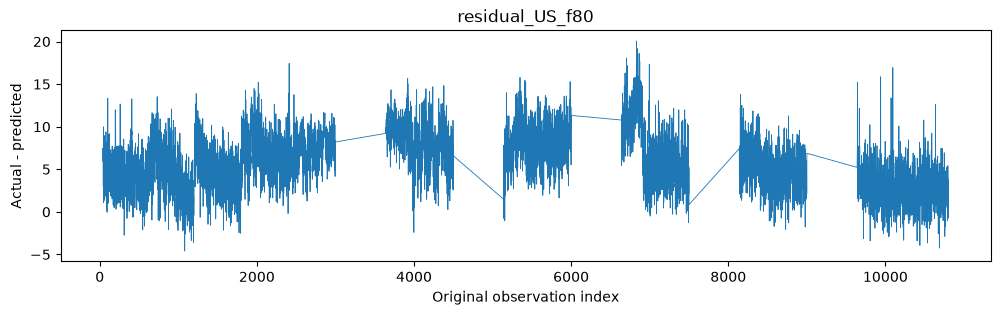

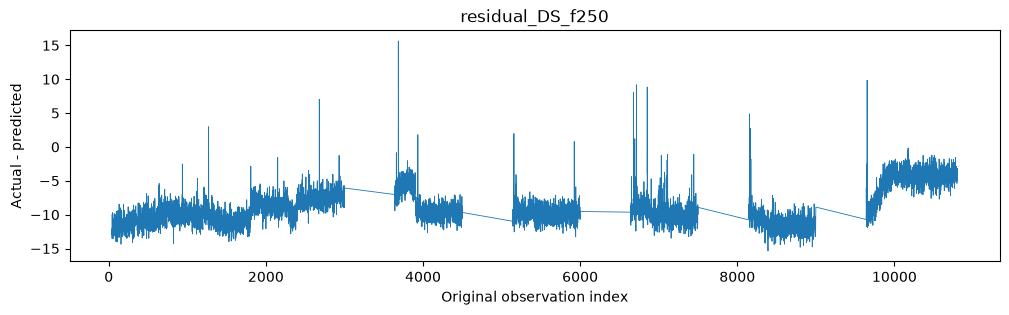

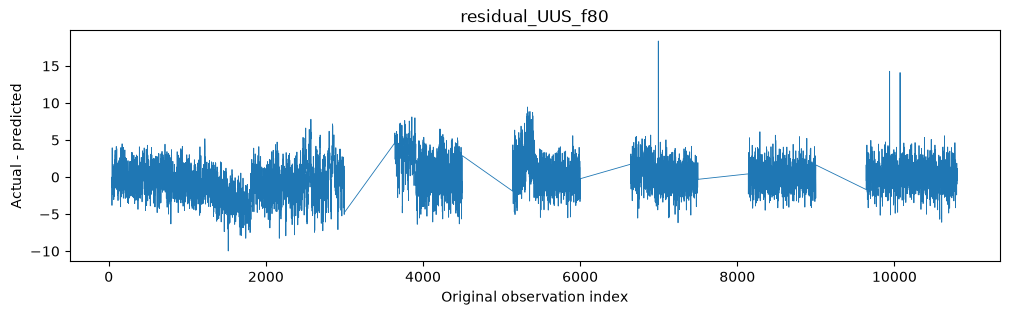

In [10]:
wide=pd.read_csv(DATA_DIR/'1212_1_actual_predicted_residual_all_channels.csv').sort_values('observation_index')
rescols=[c for c in wide if c.startswith('residual_')]
wide=wide.merge(df[['observation_index','adjacent','d_Reynolds','abs_d_Reynolds','Re_band']],on='observation_index',how='inner',validate='one_to_one')
rows=[]
for col in rescols:
    x=wide[col].astype(float);dx=x.diff().where(wide.observation_index.diff().eq(1)&wide.adjacent)
    rows.append(dict(channel=col.replace('residual_',''),n=int(x.notna().sum()),mean_signed_residual=x.mean(),RMSE=np.sqrt(np.nanmean(x**2)),corr_Re=x.corr(wide.Reynolds),corr_dRe_dResidual=dx.corr(wide.d_Reynolds),corr_absdRe_absdResidual=dx.abs().corr(wide.abs_d_Reynolds)))
channels=pd.DataFrame(rows).sort_values('RMSE',ascending=False);display(channels.head(15).round(4));channels.to_csv(OUT/'channel_residual_diagnostics.csv',index=False)
for col in ['residual_US_f80','residual_DS_f250','residual_UUS_f80']:
    if col in wide:
        fig,ax=plt.subplots(figsize=(12,3));ax.plot(wide.observation_index,wide[col],lw=.6);ax.set(xlabel='Original observation index',ylabel='Actual - predicted',title=col);plt.savefig(OUT/(col+'_tracking.png'),dpi=120);plt.show()


### Interpretation — Signed residuals across 108 channels
Large systematic healthy residual biases are present: **DS/f250** has mean actual−predicted **−8.919**, RMSE **9.299**; **US/f80** has mean **+5.824**, RMSE **6.718**. Several US channels have strong Reynolds–signed-residual correlations, including **US/f50: 0.729**, **US/f63: 0.625**, and **US/f100: 0.578**. Thus the aggregate RMSE misses important **directional and channel-specific structure**.

By contrast, the reported same-step ΔRe–Δresidual correlations for these channels are near zero. This again favors studying **Reynolds-regime-dependent residual patterns and cumulative/delayed behavior**, rather than assuming instantaneous response. The three tracking figures are illustrations of channel behavior, not causal demonstrations. Large biases warrant checking checkpoint/preprocessing compatibility and train–validation distribution shift before attributing them to model capacity. No Stage 2 false-positive timestamps are joined in this analysis, so a link from these residuals to false alarms is **not established**.

## 9. What is and is not identified

- **Observed:** conditional relationships between Reynolds levels/transitions and healthy Stage 1 error, plus within-event error dynamics.
- **Not identified:** the isolated physical causal effect of Reynolds independent of pump behavior, pressure, temperature, vibration, sensor drift or experimental scheduling. None of these variables is available in this export.
- **Time dependence:** HAC is a partial correction, not independent replication. Overlapping inference windows and one run limit effective sample size.
- **Selection:** the sample contains fully healthy windows only; observations near leaks can be excluded, potentially distorting transitions and operating-regime coverage.
- **Temporal interpretation:** contemporaneous ΔRe and ΔRMSE may reflect shared causes or time alignment; pre-trends and repeated transitions are crucial checks.
- **Next causal link:** Stage 2 false positives cannot be attributed to Stage 1 from these data alone. A separate aligned Stage 2 predictions export is needed to test that link.
- **Engineering next step:** evaluate residual invariance across normal regimes and whether proposed baseline improvements reduce false alarms **without lowering leak recall** on independent runs.

**Run instruction:** execute all cells; CSVs and figures are written to `reynolds_causal_results/`. Adjust `DATA_DIR` if needed.